In [1]:
# Cell 1: Imports
import warnings
warnings.filterwarnings("ignore")

from pathlib import Path
from datetime import datetime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.model_selection import train_test_split, StratifiedKFold, KFold, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.svm import SVR
from sklearn.ensemble import (RandomForestClassifier, GradientBoostingClassifier,
                              RandomForestRegressor, GradientBoostingRegressor)
from sklearn.metrics import (accuracy_score, f1_score, roc_auc_score, classification_report,
                             confusion_matrix, mean_absolute_error, mean_squared_error, r2_score)
from sklearn.inspection import permutation_importance

# XGBoost – proposal Table 05 baseline list
try:
    from xgboost import XGBClassifier, XGBRegressor
    XGBOOST_AVAILABLE = True
    print("XGBoost available")
except ImportError:
    XGBOOST_AVAILABLE = False
    print("XGBoost not installed  →  pip install xgboost  (running without it)")

# SHAP – proposal Section 3.6 explainability
try:
    import shap
    SHAP_AVAILABLE = True
    print("SHAP available")
except ImportError:
    SHAP_AVAILABLE = False
    print("SHAP not installed  →  pip install shap  (falling back to permutation importance)")

RANDOM_STATE = 42
pd.set_option("display.max_columns", 50)
print("Imports OK")

XGBoost not installed  →  pip install xgboost  (running without it)
SHAP not installed  →  pip install shap  (falling back to permutation importance)
Imports OK


In [2]:
# Cell 2: Load data
# CSV file එක මේ notebook එකම තියෙන folder එකේ දාන්න (components/planning/research/)
DATA_PATH = Path("it_project_data.csv")

df = pd.read_csv(DATA_PATH)
print("Shape:", df.shape)
df.head()

Shape: (250, 17)


,Project_ID,Project_Type,Department,Month,Team_Size,Planned_Duration_Days,Actual_Duration_Days,Tasks_Planned,Tasks_Completed,Bugs_Found,Bugs_Fixed,Client_Changes,Planned_Budget,Actual_Cost,Overtime_Hours,Project_Status,Client_Satisfaction
0,P001,Mobile,Development,Nov,10,60,59,69,67,40,32,4,1972280,1894578,74,Completed,4
1,P002,Web,Development,Mar,9,45,44,47,47,16,13,2,1279892,1305310,51,Ongoing,4
2,P003,ERP,Development,Aug,7,180,232,278,229,115,95,8,4716313,5472178,102,Delayed,3
3,P004,Web,Development,Jan,8,45,43,53,53,15,13,0,939984,932869,65,Completed,4
4,P005,Cloud,Infrastructure,Jul,4,90,104,143,125,35,30,6,1383712,1687954,53,Delayed,3


In [3]:
# Cell 3: Quick look at the data
print(df.isna().sum().sum(), "missing values")
print(df["Project_Status"].value_counts(), "\n")
print(df["Project_Type"].value_counts(), "\n")
df.describe().T

0 missing values
Project_Status
Delayed      173
Completed     66
Ongoing       11
Name: count, dtype: int64 

Project_Type
Web       66
Mobile    46
Data      43
ERP       35
Cloud     34
AI/ML     26
Name: count, dtype: int64 



,count,mean,std,min,25%,50%,75%,max
Team_Size,250.0,8.804,3.673085e+00,3.0,6.00,9.0,11.00,21.0
Planned_Duration_Days,250.0,113.640,4.899953e+01,45.0,60.00,120.0,150.00,180.0
Actual_Duration_Days,250.0,123.700,5.660327e+01,40.0,66.25,123.0,172.75,244.0
Tasks_Planned,250.0,171.680,8.502035e+01,45.0,96.00,166.0,244.00,351.0
Tasks_Completed,250.0,163.844,8.151588e+01,44.0,93.50,157.0,228.50,351.0
Bugs_Found,250.0,60.048,3.225211e+01,5.0,32.00,57.0,85.75,150.0
Bugs_Fixed,250.0,51.812,2.835972e+01,3.0,29.00,47.0,74.00,139.0
Client_Changes,250.0,3.804,2.183726e+00,0.0,2.00,4.0,5.00,11.0
Planned_Budget,250.0,3220901.928,1.946725e+06,354535.0,1622410.25,2808791.5,4640599.00,10722998.0
Actual_Cost,250.0,3537748.276,2.175263e+06,382512.0,1711846.25,3104698.0,5203460.75,12145318.0


In [4]:
# Cell 4: Build targets, remove ongoing projects
data = df[df["Project_Status"] != "Ongoing"].copy()

data["Is_Delayed"] = (data["Actual_Duration_Days"] > data["Planned_Duration_Days"]).astype(int)
data["Delay_Pct"] = (data["Actual_Duration_Days"] - data["Planned_Duration_Days"]) / data["Planned_Duration_Days"] * 100
data["Cost_Overrun_Pct"] = (data["Actual_Cost"] - data["Planned_Budget"]) / data["Planned_Budget"] * 100

print("Training rows:", len(data))
print("Delayed share:", round(data["Is_Delayed"].mean(), 3))
print(data[["Delay_Pct", "Cost_Overrun_Pct"]].describe().round(2))

Training rows: 239
Delayed share: 0.724
       Delay_Pct  Cost_Overrun_Pct
count     239.00            239.00
mean        7.99              9.42
std        11.31              7.37
min       -12.00             -5.48
25%         0.00              4.14
50%         7.22              9.13
75%        15.56             13.47
max        44.44             30.68


In [5]:
# Cell 5: Feature engineering (planning-time information only)
def add_features(d):
    d = d.copy()
    # Original ratio features
    d["Tasks_per_Day"]     = d["Tasks_Planned"] / d["Planned_Duration_Days"]
    d["Tasks_per_Member"]  = d["Tasks_Planned"] / d["Team_Size"]
    d["Budget_per_Task"]   = d["Planned_Budget"] / d["Tasks_Planned"]
    d["Budget_per_Day"]    = d["Planned_Budget"] / d["Planned_Duration_Days"]
    d["Budget_per_Member"] = d["Planned_Budget"] / d["Team_Size"]
    # Proposal Section 3.3 – Risk_Level / complexity indicator available at planning time
    # If dataset has a Risk_Level column, encode it; otherwise derive a proxy
    if "Risk_Level" in d.columns:
        risk_map = {"Low": 1, "Medium": 2, "High": 3}
        d["Risk_Score"] = d["Risk_Level"].map(risk_map).fillna(2)
    # Scope intensity: tasks per budget unit (proxy for scope risk)
    d["Scope_Intensity"] = d["Tasks_Planned"] / (d["Planned_Budget"] / 1_000_000 + 1e-9)
    return d

CAT_FEATURES = ["Project_Type", "Department", "Month"]

data_fe = add_features(data)

# Build NUM_FEATURES list dynamically (include Risk_Score only if derived)
base_num = ["Team_Size", "Planned_Duration_Days", "Tasks_Planned", "Planned_Budget",
            "Tasks_per_Day", "Tasks_per_Member", "Budget_per_Task",
            "Budget_per_Day", "Budget_per_Member", "Scope_Intensity"]
if "Risk_Score" in data_fe.columns:
    base_num.append("Risk_Score")
NUM_FEATURES = base_num
FEATURES     = CAT_FEATURES + NUM_FEATURES

X      = data_fe[FEATURES]
y_cls  = data_fe["Is_Delayed"]
y_delay = data_fe["Delay_Pct"]
y_cost  = data_fe["Cost_Overrun_Pct"]

preprocess = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CAT_FEATURES),
    ("num", StandardScaler(), NUM_FEATURES),
])

# One shared split so all three models are tested on the same projects
X_train, X_test, idx_train, idx_test = train_test_split(
    X, data_fe.index, test_size=0.2, random_state=RANDOM_STATE, stratify=y_cls)

print("Train:", X_train.shape, " Test:", X_test.shape)
print("Features:", FEATURES)

Train: (191, 13)  Test: (48, 13)
Features: ['Project_Type', 'Department', 'Month', 'Team_Size', 'Planned_Duration_Days', 'Tasks_Planned', 'Planned_Budget', 'Tasks_per_Day', 'Tasks_per_Member', 'Budget_per_Task', 'Budget_per_Day', 'Budget_per_Member', 'Scope_Intensity']


In [6]:
# Cell 5b: MAPE helper – proposal Table 06
try:
    from sklearn.metrics import mean_absolute_percentage_error as _mape
    def mape(y_true, y_pred):
        # Skip near-zero actuals to avoid division by zero
        mask = np.abs(y_true) > 1e-6
        return _mape(y_true[mask], y_pred[mask]) * 100
except ImportError:
    def mape(y_true, y_pred):
        mask = np.abs(y_true) > 1e-6
        return np.mean(np.abs((np.array(y_true)[mask] - np.array(y_pred)[mask])
                               / np.array(y_true)[mask])) * 100

def rmse(y_true, y_pred):
    return float(np.sqrt(mean_squared_error(y_true, y_pred)))

def regression_report(label, true, pred):
    """Print MAE / RMSE / R² / MAPE as required by proposal Table 06."""
    print(f"  {label}")
    print(f"    MAE  : {mean_absolute_error(true, pred):.2f}")
    print(f"    RMSE : {rmse(true, pred):.2f}")
    print(f"    R²   : {r2_score(true, pred):.3f}")
    print(f"    MAPE : {mape(true, pred):.1f}%")

print("Metric helpers ready")

Metric helpers ready


In [7]:
# Cell 6: Compare classifiers with 5-fold CV (+ XGBoost per proposal Table 05)
cls_candidates = {
    "LogisticRegression": LogisticRegression(max_iter=2000, class_weight="balanced"),
    "RandomForest":       RandomForestClassifier(n_estimators=300, class_weight="balanced",
                                                 min_samples_leaf=2, random_state=RANDOM_STATE),
    "GradientBoosting":   GradientBoostingClassifier(random_state=RANDOM_STATE),
}
if XGBOOST_AVAILABLE:
    cls_candidates["XGBoost"] = XGBClassifier(
        n_estimators=300, use_label_encoder=False, eval_metric="logloss",
        scale_pos_weight=(1 - y_cls.mean()) / y_cls.mean(),  # handles class imbalance
        random_state=RANDOM_STATE, verbosity=0)

cv_cls = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
rows = []
for name, model in cls_candidates.items():
    pipe = Pipeline([("prep", preprocess), ("model", model)])
    auc = cross_val_score(pipe, X_train, y_cls.loc[idx_train], cv=cv_cls, scoring="roc_auc")
    f1  = cross_val_score(pipe, X_train, y_cls.loc[idx_train], cv=cv_cls, scoring="f1")
    acc = cross_val_score(pipe, X_train, y_cls.loc[idx_train], cv=cv_cls, scoring="accuracy")
    rows.append({"model": name, "cv_auc": auc.mean(), "cv_f1": f1.mean(), "cv_acc": acc.mean()})

cls_results = pd.DataFrame(rows).sort_values("cv_auc", ascending=False)
cls_results.round(3)

,model,cv_auc,cv_f1,cv_acc
0,LogisticRegression,0.805,0.750,0.687
2,GradientBoosting,0.792,0.839,0.765
1,RandomForest,0.778,0.827,0.759


In [8]:
# Cell 7: Train best classifier and evaluate on the held-out test set
best_cls_name = cls_results.iloc[0]["model"]
print("Best classifier:", best_cls_name)

clf = Pipeline([("prep", preprocess), ("model", cls_candidates[best_cls_name])])
clf.fit(X_train, y_cls.loc[idx_train])

pred  = clf.predict(X_test)
proba = clf.predict_proba(X_test)[:, 1]
y_true_cls = y_cls.loc[idx_test]

print("\n── Test-set metrics (proposal Table 06) ──")
print("Accuracy  :", round(accuracy_score(y_true_cls, pred), 3))
print("F1        :", round(f1_score(y_true_cls, pred), 3))
print("ROC-AUC   :", round(roc_auc_score(y_true_cls, proba), 3))
print()
print(classification_report(y_true_cls, pred, target_names=["On time", "Delayed"]))
print("Confusion matrix:\n", confusion_matrix(y_true_cls, pred))

Best classifier: LogisticRegression

── Test-set metrics (proposal Table 06) ──
Accuracy  : 0.792
F1        : 0.833
ROC-AUC   : 0.916

              precision    recall  f1-score   support

     On time       0.57      1.00      0.72        13
     Delayed       1.00      0.71      0.83        35

    accuracy                           0.79        48
   macro avg       0.78      0.86      0.78        48
weighted avg       0.88      0.79      0.80        48

Confusion matrix:
 [[13  0]
 [10 25]]


In [9]:
# Cell 8: Compare regressors (delay % and cost overrun %) – full proposal Table 05 list
reg_candidates = {
    "Ridge":            Ridge(alpha=1.0),
    "RandomForest":     RandomForestRegressor(n_estimators=300, min_samples_leaf=2,
                                              random_state=RANDOM_STATE),
    "GradientBoosting": GradientBoostingRegressor(random_state=RANDOM_STATE),
    "SVR":              SVR(kernel="rbf", C=10, epsilon=0.1),
}
if XGBOOST_AVAILABLE:
    reg_candidates["XGBoost"] = XGBRegressor(
        n_estimators=300, random_state=RANDOM_STATE, verbosity=0)

cv_reg = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

def compare_regressors(y_all, label):
    out = []
    for name, model in reg_candidates.items():
        pipe = Pipeline([("prep", preprocess), ("model", model)])
        mae  = -cross_val_score(pipe, X_train, y_all.loc[idx_train], cv=cv_reg,
                                scoring="neg_mean_absolute_error").mean()
        rmse_cv = np.sqrt(-cross_val_score(pipe, X_train, y_all.loc[idx_train], cv=cv_reg,
                                           scoring="neg_mean_squared_error").mean())
        r2   = cross_val_score(pipe, X_train, y_all.loc[idx_train], cv=cv_reg,
                               scoring="r2").mean()
        out.append({"target": label, "model": name,
                    "cv_mae": mae, "cv_rmse": rmse_cv, "cv_r2": r2})
    return pd.DataFrame(out).sort_values("cv_mae")

delay_results = compare_regressors(y_delay, "Delay_Pct")
cost_results  = compare_regressors(y_cost,  "Cost_Overrun_Pct")
display(delay_results.round(3))
display(cost_results.round(3))

,target,model,cv_mae,cv_rmse,cv_r2
1,Delay_Pct,RandomForest,6.650,8.147,0.480
0,Delay_Pct,Ridge,6.752,8.273,0.466
2,Delay_Pct,GradientBoosting,7.029,8.829,0.376
3,Delay_Pct,SVR,7.380,9.252,0.348


,target,model,cv_mae,cv_rmse,cv_r2
1,Cost_Overrun_Pct,RandomForest,4.721,5.935,0.365
2,Cost_Overrun_Pct,GradientBoosting,4.953,6.436,0.242
0,Cost_Overrun_Pct,Ridge,5.242,6.483,0.240
3,Cost_Overrun_Pct,SVR,5.388,6.788,0.181


In [10]:
# Cell 9: Train best regressors and evaluate on the test set (MAE / RMSE / R² / MAPE)
def fit_best_regressor(results, y_all, label):
    best = results.iloc[0]["model"]
    pipe = Pipeline([("prep", preprocess), ("model", reg_candidates[best])])
    pipe.fit(X_train, y_all.loc[idx_train])
    pred = pipe.predict(X_test)
    true = y_all.loc[idx_test]
    print(f"\n── {label}  (best: {best}) ──")
    regression_report(label, true, pred)
    return pipe, best

delay_model, best_delay_name = fit_best_regressor(delay_results, y_delay, "Delay_Pct (%)")
cost_model,  best_cost_name  = fit_best_regressor(cost_results,  y_cost,  "Cost_Overrun_Pct (%)")

# Baseline: always predict training mean – model must beat this (proposal Table 05)
print("\n── Baseline MAE (predict the training mean) ──")
print("  Delay_Pct       :",
      round(mean_absolute_error(y_delay.loc[idx_test],
                                [y_delay.loc[idx_train].mean()] * len(idx_test)), 2))
print("  Cost_Overrun_Pct:",
      round(mean_absolute_error(y_cost.loc[idx_test],
                                [y_cost.loc[idx_train].mean()] * len(idx_test)), 2))


── Delay_Pct (%)  (best: RandomForest) ──
  Delay_Pct (%)
    MAE  : 6.33
    RMSE : 8.22
    R²   : 0.375
    MAPE : 65.4%

── Cost_Overrun_Pct (%)  (best: RandomForest) ──
  Cost_Overrun_Pct (%)
    MAE  : 4.03
    RMSE : 5.52
    R²   : 0.250
    MAPE : 143.3%

── Baseline MAE (predict the training mean) ──
  Delay_Pct       : 8.09
  Cost_Overrun_Pct: 4.8


Using permutation importance fallback...


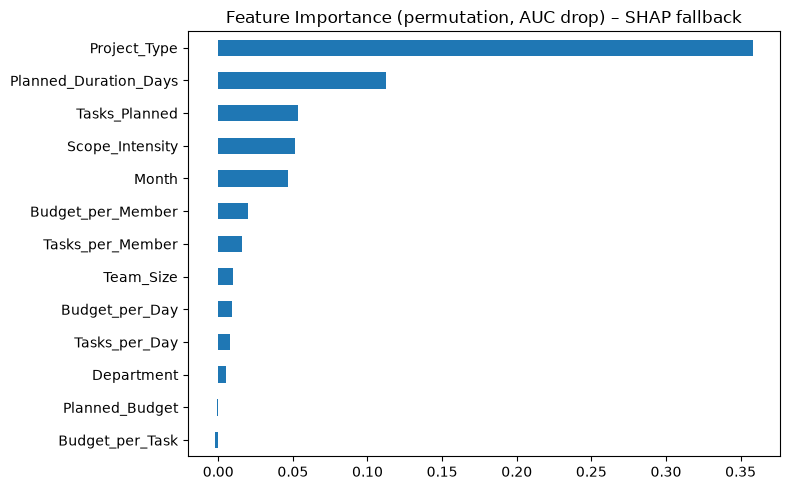

Project_Type             0.3584
Planned_Duration_Days    0.1124
Tasks_Planned            0.0537
Scope_Intensity          0.0511
Month                    0.0470
Budget_per_Member        0.0199
Tasks_per_Member         0.0159
Team_Size                0.0097
Budget_per_Day           0.0092
Tasks_per_Day            0.0078
Department               0.0053
Planned_Budget          -0.0005
Budget_per_Task         -0.0024
dtype: float64


In [11]:
# Cell 10: SHAP explanations for delay classifier (proposal Section 3.6)

# Preprocessed feature names (needed for SHAP plots)
ohe_names  = clf.named_steps["prep"].named_transformers_["cat"].get_feature_names_out(CAT_FEATURES).tolist()
all_feat_names = ohe_names + NUM_FEATURES

X_test_transformed = clf.named_steps["prep"].transform(X_test)

if SHAP_AVAILABLE:
    base_model = clf.named_steps["model"]

    # TreeExplainer works for RF, GBM, XGBoost; LinearExplainer for LR
    if best_cls_name == "LogisticRegression":
        explainer = shap.LinearExplainer(base_model, X_test_transformed,
                                         feature_names=all_feat_names)
    else:
        explainer = shap.TreeExplainer(base_model, feature_names=all_feat_names)

    shap_values = explainer(X_test_transformed)

    plt.figure(figsize=(9, 5))
    shap.summary_plot(shap_values, X_test_transformed,
                      feature_names=all_feat_names,
                      plot_type="bar", show=False)
    plt.title("SHAP Feature Importance – Delay Classifier (proposal Sec 3.6)")
    plt.tight_layout()
    plt.show()

    # Per-prediction SHAP values (top-3 drivers) → saved into bundle for API
    def top_shap_drivers(shap_vals, feat_names, n=3):
        """Return top-N driving features and their SHAP values for one prediction."""
        if hasattr(shap_vals, 'values'):
            vals = shap_vals.values
        else:
            vals = np.array(shap_vals)
        if vals.ndim == 2:
            vals = vals[:, 1]  # positive-class SHAP for classifiers
        idx = np.argsort(np.abs(vals))[::-1][:n]
        return [(feat_names[i], round(float(vals[i]), 4)) for i in idx]

    print("SHAP setup complete. Per-prediction explanation ready.")
    SHAP_EXPLAINER = explainer
    SHAP_FEAT_NAMES = all_feat_names

else:
    # Fallback: permutation importance (original approach)
    print("Using permutation importance fallback...")
    perm = permutation_importance(clf, X_test, y_cls.loc[idx_test], n_repeats=20,
                                  random_state=RANDOM_STATE, scoring="roc_auc")
    importance = (pd.Series(perm.importances_mean, index=FEATURES)
                    .sort_values(ascending=True))

    importance.plot(kind="barh", figsize=(8, 5),
                    title="Feature Importance (permutation, AUC drop) – SHAP fallback")
    plt.tight_layout()
    plt.show()
    print(importance.sort_values(ascending=False).round(4))
    SHAP_EXPLAINER   = None
    SHAP_FEAT_NAMES  = FEATURES

In [12]:
# Cell 11: Save models (joblib) for components/planning/service/analysis.py
# NFR-07 Auditability: model_version + trained_at timestamp saved in bundle
MODEL_DIR = Path("models")
MODEL_DIR.mkdir(exist_ok=True)

bundle = {
    # ── Models ────────────────────────────────────────────────────────────
    "delay_classifier":      clf,
    "delay_pct_regressor":   delay_model,
    "cost_overrun_regressor": cost_model,

    # ── Feature metadata ──────────────────────────────────────────────────
    "features":     FEATURES,
    "cat_features": CAT_FEATURES,
    "num_features": NUM_FEATURES,

    # ── Explainability artefacts (proposal Section 3.6) ───────────────────
    "shap_explainer":    SHAP_EXPLAINER,          # None if SHAP not installed
    "shap_feature_names": SHAP_FEAT_NAMES,
    "add_features_fn":   add_features,            # needed for inference preprocessing

    # ── Model selection summary ───────────────────────────────────────────
    "best_classifier":    best_cls_name,
    "best_delay_reg":     best_delay_name,
    "best_cost_reg":      best_cost_name,

    # ── Auditability (NFR-07) ─────────────────────────────────────────────
    "model_version":  "planning-v0.2",
    "trained_at":     datetime.utcnow().isoformat() + "Z",
    "dataset":        str(DATA_PATH),
    "random_state":   RANDOM_STATE,
}

joblib.dump(bundle, MODEL_DIR / "planning_models.joblib")
print("Saved to", (MODEL_DIR / "planning_models.joblib").resolve())
print("Version  :", bundle["model_version"])
print("Trained  :", bundle["trained_at"])

Saved to C:\Users\ASUS Vivobook\Desktop\planning\models\planning_models.joblib
Version  : planning-v0.2
Trained  : 2026-10-21T14:35:41.722881Z


In [13]:
# Cell 12: Test prediction for one new project (this is what analysis.py will do)
bundle_loaded = joblib.load(MODEL_DIR / "planning_models.joblib")
_add = bundle_loaded["add_features_fn"]

new_project = pd.DataFrame([{
    "Project_Type": "Web", "Department": "Development", "Month": "Mar",
    "Team_Size": 8, "Planned_Duration_Days": 90,
    "Tasks_Planned": 150, "Planned_Budget": 2_500_000,
}])
new_project = _add(new_project)[bundle_loaded["features"]]

risk      = bundle_loaded["delay_classifier"].predict_proba(new_project)[0, 1]
delay_pct = bundle_loaded["delay_pct_regressor"].predict(new_project)[0]
cost_pct  = bundle_loaded["cost_overrun_regressor"].predict(new_project)[0]

print(f"Delay probability : {risk:.0%}")
print(f"Expected delay    : {delay_pct:.1f}% of planned duration (~{delay_pct/100*90:.0f} days)")
print(f"Expected cost over: {cost_pct:.1f}% of budget")

# SHAP-based explanation for this prediction (proposal Section 3.6)
if bundle_loaded["shap_explainer"] is not None:
    prep   = bundle_loaded["delay_classifier"].named_steps["prep"]
    x_tf   = prep.transform(new_project)
    sv     = bundle_loaded["shap_explainer"](x_tf)
    drivers = top_shap_drivers(sv, bundle_loaded["shap_feature_names"])
    print("\nTop-3 delay risk drivers (SHAP):")
    for feat, val in drivers:
        direction = "↑ increases" if val > 0 else "↓ decreases"
        print(f"  {feat:30s}: {val:+.4f}  ({direction} delay risk)")

Delay probability : 17%
Expected delay    : 5.4% of planned duration (~5 days)
Expected cost over: 5.4% of budget


In [16]:
import joblib
from pathlib import Path

# Create folder
Path("models").mkdir(exist_ok=True)

# Save all trained models and related details
joblib.dump(bundle, "models/planning_models.pkl")

print("Model saved successfully!")
print("File: models/planning_models.pkl")

Model saved successfully!
File: models/planning_models.pkl


In [17]:
import os

print(os.path.abspath("models/planning_models.pkl"))
print(os.path.exists("models/planning_models.pkl"))

C:\Users\ASUS Vivobook\Desktop\planning\models\planning_models.pkl
True


In [18]:
import joblib

model_bundle = joblib.load("models/planning_models.pkl")

print("Model loaded successfully!")
print(model_bundle.keys())


Model loaded successfully!
dict_keys(['delay_classifier', 'delay_pct_regressor', 'cost_overrun_regressor', 'features', 'cat_features', 'num_features', 'shap_explainer', 'shap_feature_names', 'add_features_fn', 'best_classifier', 'best_delay_reg', 'best_cost_reg', 'model_version', 'trained_at', 'dataset', 'random_state'])


In [20]:
import joblib

loaded_bundle = joblib.load("models/planning_models.pkl")

print("Model loaded successfully!")

print("Delay Classifier:",
      type(loaded_bundle["delay_classifier"]))

print("Delay Percentage Regressor:",
      type(loaded_bundle["delay_pct_regressor"]))

print("Cost Overrun Regressor:",
      type(loaded_bundle["cost_overrun_regressor"]))

print("\nFeatures required:")
print(loaded_bundle["features"])

print("\nModel version:", loaded_bundle["model_version"])
print("Dataset:", loaded_bundle["dataset"])

Model loaded successfully!
Delay Classifier: <class 'sklearn.pipeline.Pipeline'>
Delay Percentage Regressor: <class 'sklearn.pipeline.Pipeline'>
Cost Overrun Regressor: <class 'sklearn.pipeline.Pipeline'>

Features required:
['Project_Type', 'Department', 'Month', 'Team_Size', 'Planned_Duration_Days', 'Tasks_Planned', 'Planned_Budget', 'Tasks_per_Day', 'Tasks_per_Member', 'Budget_per_Task', 'Budget_per_Day', 'Budget_per_Member', 'Scope_Intensity']

Model version: planning-v0.2
Dataset: it_project_data.csv


In [22]:
import joblib
from pathlib import Path

model_path = Path("models/planning_models.pkl")

print("Model file exists:", model_path.exists())

loaded_bundle = joblib.load(model_path)

print("Model loaded successfully!")
print("Required features:")
print(loaded_bundle["features"])

Model file exists: True
Model loaded successfully!
Required features:
['Project_Type', 'Department', 'Month', 'Team_Size', 'Planned_Duration_Days', 'Tasks_Planned', 'Planned_Budget', 'Tasks_per_Day', 'Tasks_per_Member', 'Budget_per_Task', 'Budget_per_Day', 'Budget_per_Member', 'Scope_Intensity']


In [26]:
# Get the preprocessing step
preprocessor = delay_model.named_steps["prep"]

# Display categorical columns and their accepted values
for name, transformer, columns in preprocessor.transformers_:
    if hasattr(transformer, "categories_"):
        print("\nCategorical columns:", columns)

        for col, categories in zip(columns, transformer.categories_):
            print(f"{col}: {categories}")


Categorical columns: ['Project_Type', 'Department', 'Month']
Project_Type: ['AI/ML' 'Cloud' 'Data' 'ERP' 'Mobile' 'Web']
Department: ['Data' 'Development' 'Infrastructure' 'Testing']
Month: ['Apr' 'Aug' 'Dec' 'Feb' 'Jan' 'Jul' 'Jun' 'Mar' 'May' 'Nov' 'Oct' 'Sep']


In [27]:
import pandas as pd

sample_project = pd.DataFrame([{
    "Project_Type": "Web",
    "Department": "Development",
    "Month": "Oct",
    "Team_Size": 5,
    "Planned_Duration_Days": 30,
    "Tasks_Planned": 60,
    "Planned_Budget": 10000,
    "Tasks_per_Day": 2,
    "Tasks_per_Member": 12,
    "Budget_per_Task": 166.67,
    "Budget_per_Day": 333.33,
    "Budget_per_Member": 2000,
    "Scope_Intensity": 2
}])

print(sample_project)

  Project_Type   Department Month  Team_Size  Planned_Duration_Days  \
0          Web  Development   Oct          5                     30   

   Tasks_Planned  Planned_Budget  Tasks_per_Day  Tasks_per_Member  \
0             60           10000              2                12   

   Budget_per_Task  Budget_per_Day  Budget_per_Member  Scope_Intensity  
0           166.67          333.33               2000                2  


In [28]:
delay_model = loaded_bundle["delay_classifier"]
delay_pct_model = loaded_bundle["delay_pct_regressor"]
cost_model = loaded_bundle["cost_overrun_regressor"]

try:
    delay_prediction = delay_model.predict(sample_project)
    print("Delay Prediction:", delay_prediction[0])

    delay_percentage = delay_pct_model.predict(sample_project)
    print("Estimated Delay Percentage:", delay_percentage[0])

    cost_overrun = cost_model.predict(sample_project)
    print("Estimated Cost Overrun:", cost_overrun[0])

except Exception as e:
    print("Error Type:", type(e).__name__)
    print("Error Message:", str(e))

Delay Prediction: 0
Estimated Delay Percentage: 2.196527148776408
Estimated Cost Overrun: 2.196527148776408


In [29]:
# Check whether the two regression models are actually different
print(
    "Same model object:",
    delay_pct_model is cost_model
)

print("\nDelay percentage model:")
print(delay_pct_model.named_steps["model"])

print("\nCost overrun model:")
print(cost_model.named_steps["model"])

print("\nSaved model version:")
print(loaded_bundle["model_version"])

print("\nTraining dataset:")
print(loaded_bundle["dataset"])

Same model object: False

Delay percentage model:
RandomForestRegressor(min_samples_leaf=2, n_estimators=300, random_state=42)

Cost overrun model:
RandomForestRegressor(min_samples_leaf=2, n_estimators=300, random_state=42)

Saved model version:
planning-v0.2

Training dataset:
it_project_data.csv


In [30]:
print("Delay percentage model:")
print(delay_pct_model)

print("\nCost overrun model:")
print(cost_model)

print(
    "\nAre both the same object?",
    delay_pct_model is cost_model
)

Delay percentage model:
Pipeline(steps=[('prep',
                 ColumnTransformer(transformers=[('cat',
                                                  OneHotEncoder(handle_unknown='ignore',
                                                                sparse_output=False),
                                                  ['Project_Type', 'Department',
                                                   'Month']),
                                                 ('num', StandardScaler(),
                                                  ['Team_Size',
                                                   'Planned_Duration_Days',
                                                   'Tasks_Planned',
                                                   'Planned_Budget',
                                                   'Tasks_per_Day',
                                                   'Tasks_per_Member',
                                                   'Budget_per_Task',
               

In [31]:
import joblib
from pathlib import Path

Path("models").mkdir(exist_ok=True)

joblib.dump(
    loaded_bundle,
    "models/planning_models_final.pkl"
)

print("Final model bundle saved successfully!")
print("File: models/planning_models_final.pkl")

Final model bundle saved successfully!
File: models/planning_models_final.pkl


In [32]:
import joblib
from pathlib import Path

final_path = Path("models/planning_models_final.pkl")

print("File exists:", final_path.exists())
print("File size:", round(final_path.stat().st_size / 1024, 2), "KB")

final_bundle = joblib.load(final_path)

print("Final bundle loaded successfully!")
print("Model version:", final_bundle["model_version"])
print("Available models:", [
    "delay_classifier",
    "delay_pct_regressor",
    "cost_overrun_regressor"
])

File exists: True
File size: 2317.94 KB
Final bundle loaded successfully!
Model version: planning-v0.2
Available models: ['delay_classifier', 'delay_pct_regressor', 'cost_overrun_regressor']


In [33]:
from IPython.display import FileLink, display
from pathlib import Path

file_path = Path("models/planning_models_final.pkl")

if file_path.exists():
    display(FileLink(str(file_path)))
else:
    print("File not found. Check the file path.")

C:\Users\ASUS Vivobook\Desktop\planning\models\planning_models_final.pkl

In [34]:

import joblib

loaded_bundle = joblib.load("models/planning_models_final.pkl")

print("Model loaded successfully!")
print(loaded_bundle["model_version"])
      

Model loaded successfully!
planning-v0.2
